In [3]:
import re
import os
import warnings
import pymysql
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, classification_report
import xgboost as xgb
import lightgbm as lgb
warnings.filterwarnings('ignore')

_KO_FONTS = ['NanumGothic', 'Malgun Gothic', 'AppleGothic']
_available = {f.name for f in fm.fontManager.ttflist}
_ko_font = next((f for f in _KO_FONTS if f in _available), None)
if _ko_font:
    plt.rcParams['font.family'] = _ko_font
plt.rcParams['axes.unicode_minus'] = False

# ── 경로 설정 ─────────────────────────────────────────────────────────────
PACER_DIR   = './csv_2016'
DATA_DIR    = './data_v2'
NPE_CSV     = './NPE 기업목록(20260611).csv'

# ── DB 접속 정보 (AI_Evaluation @ 192.168.1.116) ────────────────────────
DB_HOST = '192.168.1.116'
DB_USER = 'root'
DB_PW   = 'doslvkdlqm!'

RANDOM_STATE = 42
CV_FOLDS     = 5

# pv_L.pkl 존재 여부 확인
PV_L_PATH = f'{DATA_DIR}/pv_L.pkl'
if not os.path.exists(PV_L_PATH):
    print(f'⚠️  {PV_L_PATH} 없음 → 20260611 특허소송예측 데이터구축_v2.ipynb 먼저 실행 필요')
else:
    print(f'✅  {PV_L_PATH} 확인')

print('환경 설정 완료')

✅  ./data_v2/pv_L.pkl 확인
환경 설정 완료


---
## 1. 기존 NPE 4피처 로드
`us_transfer_register_litigation` 테이블에서 기업별 4피처 추출 

In [4]:
conn_ai = pymysql.connect(
    host=DB_HOST, user=DB_USER, password=DB_PW,
    database='AI_Evaluation', charset='utf8mb4'
)

df_liti = pd.read_sql(
    """
    SELECT RGTR_NM, RAW_RGTR_NM,
           PLAINTIFF_COUNT  AS 원고수,
           DEFENDANT_COUNT  AS 피고수,
           REGISTER_COUNT   AS 특허수,
           TRANSFER_COUNT   AS 권리자이전수
    FROM us_transfer_register_litigation
    WHERE RGTR_NM IS NOT NULL
    """,
    conn_ai
)
conn_ai.close()

print(f'us_transfer_register_litigation: {len(df_liti):,}건')
print(df_liti[['원고수','피고수','특허수','권리자이전수']].describe().round(1))

us_transfer_register_litigation: 341,367건
            원고수       피고수       특허수    권리자이전수
count  341367.0  341367.0  341367.0  341367.0
mean        0.2       0.3      19.2      12.6
std         4.5       5.4     514.8     173.6
min         0.0       0.0       0.0       1.0
25%         0.0       0.0       0.0       1.0
50%         0.0       0.0       0.0       2.0
75%         0.0       0.0       2.0       4.0
max      1621.0    1026.0  155982.0   43506.0


---
## 2. 기업명 정규화 함수 & NPE 레이블 생성

In [5]:
# 기업명 정규화 (20260609 데이터구축 노트북과 동일 로직)
_STATE_PAT  = re.compile(r'\bA\s+(?:CORPORATION\s+)?OF\s+\w{2,4}\.?\b', re.IGNORECASE)
_AKA_PAT    = re.compile(
    r'[,\s]*(?:A/K/A|D/B/A|F/K/A|T/A|AKA|DBA|FKA|'
    r'ALSO\s+KNOWN\s+AS|DOING\s+BUSINESS\s+AS|FORMERLY\s+KNOWN\s+AS|TRADING\s+AS)\b.*$',
    re.IGNORECASE
)
_SUFFIX_PAT = re.compile(
    r'\b(INCORPORATED|CORPORATION|COMPANY|LIMITED|ENTERPRISES|'
    r'INC|CORP|LLC|LTD|CO|PLC|LP|LLP|GMBH|AG|SA|SL|SRL|BV|NV|AB|AS|KK|THE|AND)\b',
    re.IGNORECASE
)

def normalize_company(name):
    if pd.isna(name): return None
    s = str(name).upper().strip()
    s = _STATE_PAT.sub(' ', s)
    s = re.sub(r'\.', '', s)
    s = _AKA_PAT.sub('', s)
    s = re.sub(r'[^\w\s]', ' ', s)
    s = _SUFFIX_PAT.sub(' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s if s else None

df_liti['rgtr_norm'] = df_liti['RGTR_NM'].apply(normalize_company)
print(f'정규화 완료. null: {df_liti["rgtr_norm"].isna().sum()}건')

정규화 완료. null: 36건


In [6]:
# NPE 기업목록 로드
npe_df = pd.read_csv(NPE_CSV, encoding='utf-8-sig')
print(f'NPE 목록: 모기업 {npe_df["company_name"].nunique():,}개 / 자회사 {npe_df["subcompany_name"].nunique():,}개')

# 모기업 + 자회사 전체 정규화 집합
npe_names_raw  = set(npe_df['company_name'].dropna()) | set(npe_df['subcompany_name'].dropna())
npe_names_norm = {normalize_company(n) for n in npe_names_raw if normalize_company(n)}
print(f'정규화된 NPE 이름 집합: {len(npe_names_norm):,}개')

def is_npe(name):
    n = normalize_company(name)
    if not n: return 0
    if n in npe_names_norm: return 1
    if len(n) >= 4:
        for npe in npe_names_norm:
            if len(npe) >= 4 and (n in npe or npe in n): return 1
    return 0

# us_transfer_register_litigation 기업에 NPE 레이블 부여
df_liti['is_npe'] = df_liti['RGTR_NM'].apply(is_npe)

n_npe  = df_liti['is_npe'].sum()
n_tot  = len(df_liti)
print(f'\nNPE 레이블: {n_npe:,}개 / 전체 {n_tot:,}개 ({n_npe/n_tot:.1%})')

NPE 목록: 모기업 574개 / 자회사 2,342개
정규화된 NPE 이름 집합: 2,341개

NPE 레이블: 5,239개 / 전체 341,367개 (1.5%)


---
## 3. 원고 → 특허 매핑 구축
PACER `names.csv` + `patents.csv`로 원고 기업명 ↔ 특허 ID 연결

In [8]:
names   = pd.read_csv(f'{PACER_DIR}/names.csv',   dtype=str)
patents = pd.read_csv(f'{PACER_DIR}/patents.csv',  dtype=str)
cases   = pd.read_csv(f'{PACER_DIR}/cases.csv',    dtype=str)

# 침해소송(case_type_1=1)만
inf_ids = set(cases[cases['case_type_1'] == '1']['case_row_id'])

# 원고 추출 (케이스당 대표 원고 1명)
plaintiffs = (
    names[
        (names['party_type'] == 'Plaintiff') &
        (names['case_row_id'].isin(inf_ids))
    ][['case_row_id', 'name']]
    .drop_duplicates('case_row_id')
    .rename(columns={'name': 'plaintiff'})
)

# 특허 추출
pat_inf = (
    patents[
        (patents['case_row_id'].isin(inf_ids)) &
        (patents['patent_doc_type'] == 'Patent')
    ][['case_row_id', 'patent']]
    .dropna()
)

# 원고 ↔ 특허 연결
plt_pat = (
    plaintiffs.merge(pat_inf, on='case_row_id', how='inner')
    .drop_duplicates(['plaintiff', 'patent'])
)
plt_pat['patent_id'] = pd.to_numeric(plt_pat['patent'], errors='coerce')
plt_pat['plt_norm']  = plt_pat['plaintiff'].apply(normalize_company)
plt_pat = plt_pat.dropna(subset=['patent_id', 'plt_norm'])
plt_pat['patent_id'] = plt_pat['patent_id'].astype(int)

print(f'원고 수       : {plt_pat["plt_norm"].nunique():,}개')
print(f'특허 수       : {plt_pat["patent_id"].nunique():,}개')
print(f'원고-특허 매핑 : {len(plt_pat):,}행')

원고 수       : 12,589개
특허 수       : 33,203개
원고-특허 매핑 : 43,321행


---
## 4. 소송예측 피처 로드 & 기업 단위 집계
`pv_L.pkl` (특허단위 27피처) → 원고 기업 단위 mean/max 집계

In [10]:
FEATURE_COLS = [
    'MCD', 'SCD',
    'TD_A', 'TD_B', 'TD_C', 'TD_D', 'TD_E', 'TD_F', 'TD_G', 'TD_H',
    'ABS', 'CTS', 'CTC', 'PTS',
    'PK', 'SK', 'PPS',
    'CD', 'IC', 'IE', 'FIE', 'ET',
    'TCP',
    'LT1', 'LI3', 'LI5', 'LI7'
]

pv_L = pd.read_pickle(PV_L_PATH)
print(f'pv_L: {len(pv_L):,}건  컬럼: {pv_L.columns.tolist()}')

feat_avail = [c for c in FEATURE_COLS if c in pv_L.columns]
print(f'사용 가능한 피처: {len(feat_avail)}/{len(FEATURE_COLS)}개')
print(f'  누락: {set(FEATURE_COLS) - set(feat_avail)}')

pv_L: 33,657건  컬럼: ['patent_id', 'PK', 'SK', 'PPS', 'ET', 'IE', 'FIE', 'ABS', 'MCD', 'SCD', 'TD_A', 'TD_B', 'TD_C', 'TD_D', 'TD_E', 'TD_F', 'TD_G', 'TD_H', 'CTS', 'PTS', 'CTC']
사용 가능한 피처: 20/27개
  누락: {'LI5', 'CD', 'IC', 'LT1', 'LI3', 'TCP', 'LI7'}


In [11]:
# 원고-특허 매핑 + pv_L 피처 조인
plt_feat = plt_pat[['plt_norm', 'patent_id']].merge(
    pv_L[['patent_id'] + feat_avail],
    on='patent_id', how='inner'
)
print(f'매핑 성공: {len(plt_feat):,}행 (원고 {plt_feat["plt_norm"].nunique():,}개)')

# 기업 단위 집계: mean + max
agg_mean = (
    plt_feat.groupby('plt_norm')[feat_avail]
    .mean()
    .rename(columns={c: f'{c}_mean' for c in feat_avail})
    .reset_index()
)
agg_max = (
    plt_feat.groupby('plt_norm')[feat_avail]
    .max()
    .rename(columns={c: f'{c}_max' for c in feat_avail})
    .reset_index()
)
agg_pat_cnt = (
    plt_feat.groupby('plt_norm')['patent_id']
    .nunique()
    .rename('소송특허수')
    .reset_index()
)

df_new_feat = agg_mean.merge(agg_max, on='plt_norm').merge(agg_pat_cnt, on='plt_norm')
print(f'집계 완료: {len(df_new_feat):,}개 기업 / {len(df_new_feat.columns)-1}개 피처')

매핑 성공: 43,321행 (원고 12,589개)
집계 완료: 12,589개 기업 / 41개 피처


---
## 5. 피처 병합 & 데이터셋 구성

In [12]:
# us_transfer_register_litigation (기존 4피처 + NPE 레이블) + 집계 신규 피처 병합
df_merged = df_liti[['rgtr_norm', '원고수', '피고수', '특허수', '권리자이전수', 'is_npe']].merge(
    df_new_feat.rename(columns={'plt_norm': 'rgtr_norm'}),
    on='rgtr_norm', how='left'
)

n_matched = df_merged[f'{feat_avail[0]}_mean'].notna().sum()
print(f'전체 기업: {len(df_merged):,}개')
print(f'신규 피처 매칭 성공: {n_matched:,}개 ({n_matched/len(df_merged):.1%})')
print(f'NPE: {df_merged["is_npe"].sum():,}개 / 비NPE: {(df_merged["is_npe"]==0).sum():,}개')

# 결측 처리: 신규 피처 미매칭 기업은 0으로 채움 (소송 이력 없음)
new_feat_cols = [c for c in df_merged.columns if c.endswith('_mean') or c.endswith('_max') or c == '소송특허수']
df_merged[new_feat_cols] = df_merged[new_feat_cols].fillna(0)

print(f'\n최종 피처 수 — 기존: 4개 / 확장: {len(new_feat_cols)}개')

전체 기업: 341,367개
신규 피처 매칭 성공: 12,206개 (3.6%)
NPE: 5,239개 / 비NPE: 336,128개

최종 피처 수 — 기존: 4개 / 확장: 41개


---
## 6. 모델 학습 및 비교

| 실험 | 피처 |
|------|------|
| **Baseline** | 기존 4피처 (원고수·피고수·특허수·권리자이전수) |
| **Extended** | 기존 4피처 + 소송예측 집계 피처 (mean/max) |

In [13]:
BASELINE_FEATS = ['원고수', '피고수', '특허수', '권리자이전수']
EXTENDED_FEATS = BASELINE_FEATS + new_feat_cols

y = df_merged['is_npe'].values

MODELS = {
    'LR'   : LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE),
    'RF'   : RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=RANDOM_STATE),
    'XGB'  : xgb.XGBClassifier(n_estimators=200, scale_pos_weight=(y==0).sum()/(y==1).sum(),
                                eval_metric='logloss', random_state=RANDOM_STATE, verbosity=0),
    'LGBM' : lgb.LGBMClassifier(n_estimators=200, scale_pos_weight=(y==0).sum()/(y==1).sum(),
                                 random_state=RANDOM_STATE, verbosity=-1),
}

cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
results = {}

for exp_name, feat_cols in [('Baseline (4피처)', BASELINE_FEATS), ('Extended (4+집계)', EXTENDED_FEATS)]:
    X = df_merged[feat_cols].values
    scaler = StandardScaler()
    X_sc = scaler.fit_transform(X)

    print(f'\n=== {exp_name} ({len(feat_cols)}개 피처) ===')
    results[exp_name] = {}

    for m_name, model in MODELS.items():
        auc  = cross_val_score(model, X_sc, y, cv=cv, scoring='roc_auc').mean()
        f1   = cross_val_score(model, X_sc, y, cv=cv, scoring='f1').mean()
        prec = cross_val_score(model, X_sc, y, cv=cv, scoring='precision').mean()
        rec  = cross_val_score(model, X_sc, y, cv=cv, scoring='recall').mean()

        results[exp_name][m_name] = {'AUC': auc, 'F1': f1, 'Precision': prec, 'Recall': rec}
        print(f'  {m_name:<6}  AUC={auc:.4f}  F1={f1:.4f}  P={prec:.4f}  R={rec:.4f}')


=== Baseline (4피처) (4개 피처) ===
  LR      AUC=0.6329  F1=0.1091  P=0.0706  R=0.2397
  RF      AUC=0.5281  F1=0.0461  P=0.0254  R=0.2474
  XGB     AUC=0.5887  F1=0.0540  P=0.0294  R=0.3417
  LGBM    AUC=0.6137  F1=0.0563  P=0.0304  R=0.3869

=== Extended (4+집계) (45개 피처) ===
  LR      AUC=0.6430  F1=0.1228  P=0.0821  R=0.2436
  RF      AUC=0.5091  F1=0.0427  P=0.0240  R=0.1964
  XGB     AUC=0.5918  F1=0.0597  P=0.0329  R=0.3232
  LGBM    AUC=0.6215  F1=0.0585  P=0.0317  R=0.3882


In [14]:
# 비교 요약 테이블
rows = []
for exp, model_dict in results.items():
    for model_name, metrics in model_dict.items():
        rows.append({'실험': exp, '모델': model_name, **metrics})

df_result = pd.DataFrame(rows).sort_values(['모델', '실험']).reset_index(drop=True)
print('=== 성능 비교 요약 ===')
display(df_result.round(4))

# AUC 기준 향상 여부
print('\n=== AUC 향상 (Extended - Baseline) ===')
for m_name in MODELS:
    base_auc = results['Baseline (4피처)'][m_name]['AUC']
    ext_auc  = results['Extended (4+집계)'][m_name]['AUC']
    diff = ext_auc - base_auc
    sign = '+' if diff >= 0 else ''
    print(f'  {m_name:<6}  {base_auc:.4f} → {ext_auc:.4f}  ({sign}{diff:.4f})')

=== 성능 비교 요약 ===


,실험,모델,AUC,F1,Precision,Recall
0,Baseline (4피처),LGBM,0.6137,0.0563,0.0304,0.3869
1,Extended (4+집계),LGBM,0.6215,0.0585,0.0317,0.3882
2,Baseline (4피처),LR,0.6329,0.1091,0.0706,0.2397
3,Extended (4+집계),LR,0.6430,0.1228,0.0821,0.2436
4,Baseline (4피처),RF,0.5281,0.0461,0.0254,0.2474
5,Extended (4+집계),RF,0.5091,0.0427,0.0240,0.1964
6,Baseline (4피처),XGB,0.5887,0.0540,0.0294,0.3417
7,Extended (4+집계),XGB,0.5918,0.0597,0.0329,0.3232



=== AUC 향상 (Extended - Baseline) ===
  LR      0.6329 → 0.6430  (+0.0100)
  RF      0.5281 → 0.5091  (-0.0190)
  XGB     0.5887 → 0.5918  (+0.0030)
  LGBM    0.6137 → 0.6215  (+0.0078)


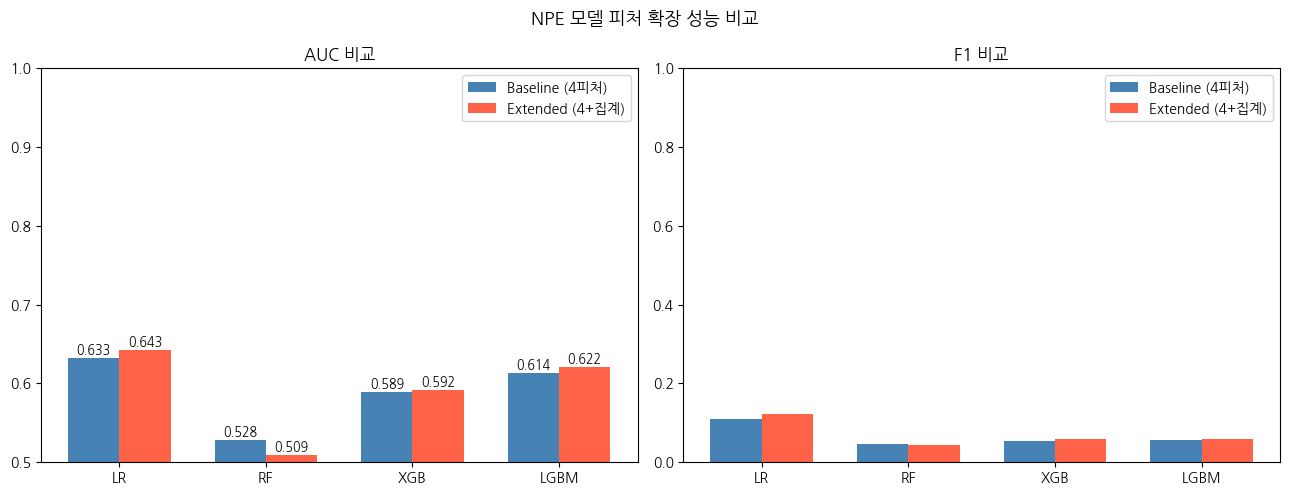

In [15]:
# 시각화: AUC 비교 bar chart
model_names = list(MODELS.keys())
baseline_aucs = [results['Baseline (4피처)'][m]['AUC'] for m in model_names]
extended_aucs = [results['Extended (4+집계)'][m]['AUC'] for m in model_names]

x = np.arange(len(model_names))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# AUC
axes[0].bar(x - width/2, baseline_aucs, width, label='Baseline (4피처)', color='steelblue')
axes[0].bar(x + width/2, extended_aucs, width, label='Extended (4+집계)', color='tomato')
axes[0].set_xticks(x); axes[0].set_xticklabels(model_names)
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title('AUC 비교'); axes[0].legend()
for i in range(len(model_names)):
    axes[0].text(i - width/2, baseline_aucs[i] + 0.005, f'{baseline_aucs[i]:.3f}', ha='center', fontsize=9)
    axes[0].text(i + width/2, extended_aucs[i] + 0.005, f'{extended_aucs[i]:.3f}', ha='center', fontsize=9)

# F1
baseline_f1s = [results['Baseline (4피처)'][m]['F1'] for m in model_names]
extended_f1s = [results['Extended (4+집계)'][m]['F1'] for m in model_names]
axes[1].bar(x - width/2, baseline_f1s, width, label='Baseline (4피처)', color='steelblue')
axes[1].bar(x + width/2, extended_f1s, width, label='Extended (4+집계)', color='tomato')
axes[1].set_xticks(x); axes[1].set_xticklabels(model_names)
axes[1].set_ylim(0, 1.0)
axes[1].set_title('F1 비교'); axes[1].legend()

plt.suptitle('NPE 모델 피처 확장 성능 비교', fontsize=13)
plt.tight_layout()
plt.show()

---
## 7. Feature Importance (Best 모델)
확장 피처 중 실제로 기여하는 변수 확인

In [ ]:
#LGBM Extended로 전체 학습 후 Feature Importance
X_ext = df_merged[EXTENDED_FEATS].values
scaler_ext = StandardScaler()
X_ext_sc = scaler_ext.fit_transform(X_ext)

lgbm_final = lgb.LGBMClassifier()